<a href="https://colab.research.google.com/github/Nasim-Amani/tag-recommender-agent-learning/blob/main/02_Collaborative_Filtering_DataScience_Concepts_video.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Video summary: Collaborative Filtering (concepts only)
**Source:** [YouTube video](https://www.youtube.com/watch?v=Fmtorg_dmM0)
**Topic:** The idea behind collaborative filtering, cosine similarity, and similarity-weighted predictions, explained with a toy example

> The video has no code. The small code cells in this notebook only draw the figures (in Colab they are folded; click a title to see the code).

---

## 1. Goal of the video
Explain **collaborative filtering** intuitively: how a recommender decides what to show a user next, using the ratings of *other* users.

**Key idea:** *past similar preferences can inform future preferences.*
If two users gave roughly the same ratings to the same shows, they have similar taste. So, to recommend something to one of them, look at what the *other* one liked.

Real-life version: *"I might like what my friends like, because my friends are similar to me."*

## 2. The setting: "StatFlix"
A made-up streaming service for statistics shows.
- Users rate shows from **1 to 5** (5 = loved it).
- Many users don't rate many shows, so the rating table has **blank cells**.
- **Question:** a user logs in. Which show should we recommend next?

In [1]:
#@title Plot setup + toy data
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch

plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
BLUE, ORANGE, GREY, GREEN, RED = "#2f6db5", "#e07b28", "#8a8a8a", "#3a9a5b", "#c0392b"

# Toy rating table (NaN = not rated). Reconstructed from the numbers in the video.
users = ["U1", "U2", "U3"]
shows = [f"Show {i}" for i in range(1, 9)]
R = np.array([
    #  1       2       3       4       5       6       7       8
    [5,      1,      4,      np.nan, np.nan, np.nan, 2,      4     ],  # U1
    [5,      1,      3,      2,      5,      np.nan, 2,      np.nan],  # U2
    [1,      4,      2,      5,      2,      np.nan, 5,      1     ],  # U3
])

## 3. The example: 3 users, 8 shows
- Rows = users U1, U2, U3. Columns = 8 shows. Blank = not rated (maybe not watched yet).
- **U1** has rated 5 shows and hasn't watched **Show 4, 5, 6** → which one should we recommend?


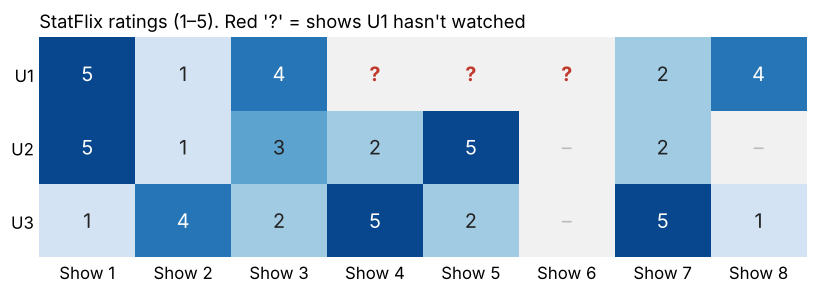

In [ ]:
#@title Figure: rating table
fig, ax = plt.subplots(figsize=(9, 2.6))
cmap = plt.get_cmap("Blues").copy(); cmap.set_bad("#f1f1f1")
ax.imshow(np.ma.masked_invalid(R), cmap=cmap, vmin=0, vmax=5.5, aspect="auto")
for i in range(R.shape[0]):
    for j in range(R.shape[1]):
        v = R[i, j]
        txt, col = ("?", RED) if (i == 0 and np.isnan(v)) else (("–", "#bbb") if np.isnan(v) else (f"{v:.0f}", "white" if v >= 4 else "#222"))
        ax.text(j, i, txt, ha="center", va="center", fontsize=13, weight="bold" if txt == "?" else None, color=col)
ax.set_xticks(range(8), shows); ax.set_yticks(range(3), users)
ax.tick_params(length=0)
for s in ax.spines.values(): s.set_visible(False)
ax.set_title("StatFlix ratings (1–5). Red '?' = shows U1 hasn't watched", loc="left", fontsize=12)
plt.show()

## 4. The naive approach: plain average
Ignore who is similar to whom and just average the other users' ratings:

| | U2 | U3 | Plain average |
|---|---|---|---|
| Show 4 | 2 | 5 | **3.5** |
| Show 5 | 5 | 2 | **3.5** |
| Show 6 | – | – | no data |

Both shows get 3.5, so we **still can't decide**. We need to use the fact that some users are more like U1 than others.

## 5. Who is U1 similar to?
Compare U1 with each other user, using **only the shows both of them rated** (pairs where one user is blank are dropped).

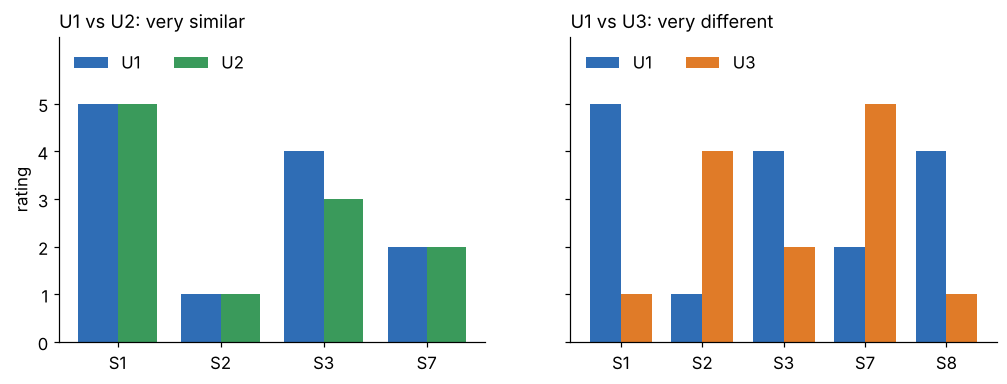

In [ ]:
#@title Figure: U1 vs U2 and U1 vs U3
def common_pairs(a, b):
    """Ratings of users a and b on shows both have rated."""
    mask = ~np.isnan(R[a]) & ~np.isnan(R[b])
    return [shows[j] for j in np.where(mask)[0]], R[a][mask], R[b][mask]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, other, verdict in [(axes[0], 1, "very similar"), (axes[1], 2, "very different")]:
    names, a, b = common_pairs(0, other)
    x = np.arange(len(names)); w = 0.38
    ax.bar(x - w/2, a, w, color=BLUE, label="U1")
    ax.bar(x + w/2, b, w, color=ORANGE if other == 2 else GREEN, label=users[other])
    ax.set_xticks(x, [n.replace("Show ", "S") for n in names]); ax.set_ylim(0, 6.4); ax.set_yticks(range(6))
    ax.set_title(f"U1 vs {users[other]}: {verdict}", loc="left", fontsize=12)
    ax.legend(frameon=False, ncol=2, loc="upper left")
axes[0].set_ylabel("rating")
plt.show()

**What the two charts show** (each pair of bars is one show both users rated):
- **U1 vs U2 (left):** almost identical ratings. The only difference is a 4 vs a 3. → If U2 likes something, U1 probably will too.
- **U1 vs U3 (right):** they disagree on nearly everything (e.g. 5 vs 1, 1 vs 4). → U3's taste tells us little about U1.

## 6. Measuring similarity: cosine similarity
We need a **number** for "how similar". The most common choice (not the only one) is **cosine similarity**.

Treat each user's ratings (on common shows) as a vector, and measure the **angle** between the two vectors:

$$\text{sim}(i, j) = \cos(\theta) = \frac{\mathbf{r}_i \cdot \mathbf{r}_j}{\lVert \mathbf{r}_i \rVert \, \lVert \mathbf{r}_j \rVert}$$

- Vectors pointing in a **similar direction** → small angle → cosine close to **1** → similar users.
- Vectors pointing **apart** → bigger angle → smaller cosine → less similar.

The real vectors have 4–5 dimensions, but the idea is easiest to see in 2D:

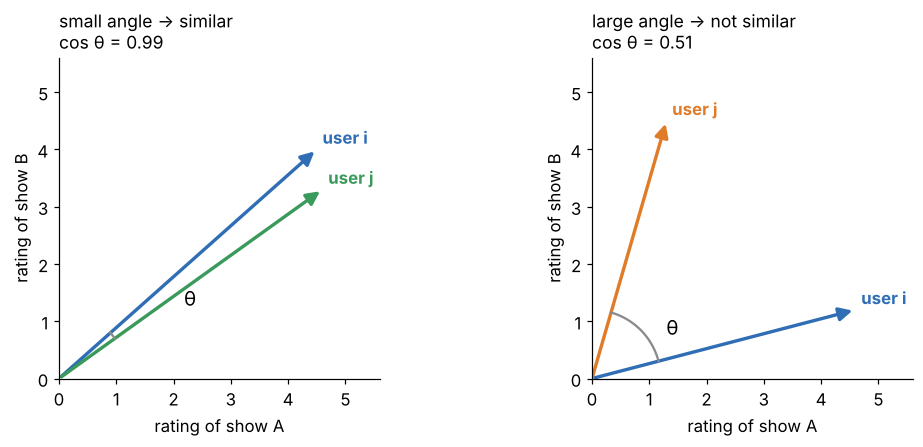

In [ ]:
#@title Figure: cosine similarity as an angle
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, (v1, v2, col, label) in zip(axes, [((4.5, 4.0), (4.6, 3.3), GREEN, "small angle → similar"),
                                           ((4.6, 1.2), (1.3, 4.5), ORANGE, "large angle → not similar")]):
    for v, c, n in [(v1, BLUE, "user i"), (v2, col, "user j")]:
        ax.add_patch(FancyArrowPatch((0, 0), v, arrowstyle="-|>", mutation_scale=18, color=c, lw=2.2))
        ax.text(v[0] + 0.1, v[1] + 0.1, n, color=c, fontsize=11, weight="bold")
    a1, a2 = np.arctan2(v1[1], v1[0]), np.arctan2(v2[1], v2[0])
    t = np.linspace(min(a1, a2), max(a1, a2), 30)
    ax.plot(1.2 * np.cos(t), 1.2 * np.sin(t), color=GREY)
    cos = np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2))
    r_lab = 1.6 if abs(a1 - a2) > 0.5 else 2.6
    ax.text(r_lab * np.cos(t.mean()) + 0.15, r_lab * np.sin(t.mean()) - 0.35, "θ", fontsize=13)
    ax.set_xlim(0, 5.6); ax.set_ylim(0, 5.6); ax.set_aspect("equal")
    ax.set_xlabel("rating of show A"); ax.set_ylabel("rating of show B")
    ax.set_title(f"{label}\ncos θ = {cos:.2f}", loc="left", fontsize=11.5)
plt.tight_layout(); plt.show()

**Results in the example:**
- sim(U1, U2) = **0.99** (almost the maximum)
- sim(U1, U3) = **0.57** (much lower)

This matches what we saw by eye in Section 5.

## 7. Prediction: a similarity-weighted average
Instead of a plain average, give each user's rating a **weight equal to their similarity to U1**, then divide by the sum of the weights (they don't add up to 1, so we normalise to stay on the 1–5 scale):

$$\hat{r}_{1,4} = \frac{s_{12}\, r_{2,4} + s_{13}\, r_{3,4}}{s_{12} + s_{13}}
= \frac{0.99 \times 2 + 0.57 \times 5}{0.99 + 0.57} \approx 3.1$$

$$\hat{r}_{1,5} = \frac{0.99 \times 5 + 0.57 \times 2}{0.99 + 0.57} \approx 3.9$$

($s_{12}$ = similarity between U1 and U2; $r_{2,4}$ = U2's rating of Show 4.)

**Why do the numbers move this way?**
- Show 4: U2 (the similar user) **disliked** it (2) → the estimate drops from 3.5 to **3.1**.
- Show 5: U2 **loved** it (5) → the estimate rises from 3.5 to **3.9**.

**→ Recommend Show 5 to U1.**

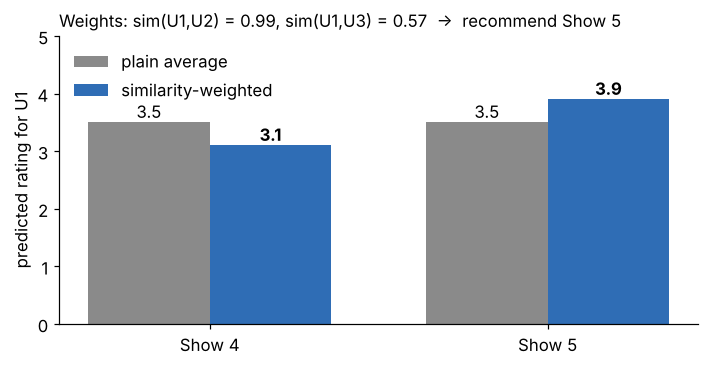

In [ ]:
#@title Figure: plain vs weighted prediction
def cosine(a, b):
    _, x, y = common_pairs(a, b)
    return x @ y / (np.linalg.norm(x) * np.linalg.norm(y))

s12, s13 = cosine(0, 1), cosine(0, 2)
pred = {}
for j in (3, 4):  # Show 4 and Show 5 (0-based index)
    plain = np.nanmean(R[1:, j])
    weighted = (s12 * R[1, j] + s13 * R[2, j]) / (s12 + s13)
    pred[shows[j]] = (plain, weighted)

fig, ax = plt.subplots(figsize=(7.5, 3.4))
x = np.arange(2); w = 0.36
ax.bar(x - w/2, [p[0] for p in pred.values()], w, color=GREY, label="plain average")
ax.bar(x + w/2, [p[1] for p in pred.values()], w, color=BLUE, label="similarity-weighted")
for k, (p, wv) in enumerate(pred.values()):
    ax.text(k - w/2, p + 0.08, f"{p:.1f}", ha="center"); ax.text(k + w/2, wv + 0.08, f"{wv:.1f}", ha="center", weight="bold")
ax.set_xticks(x, list(pred)); ax.set_ylim(0, 5); ax.set_ylabel("predicted rating for U1")
ax.legend(frameon=False, loc="upper left")
ax.set_title(f"Weights: sim(U1,U2) = {s12:.2f}, sim(U1,U3) = {s13:.2f}  →  recommend Show 5", loc="left", fontsize=11)
plt.show()

## 8. Where the name comes from
- **Filtering:** automatically predicting what a user will like (filtering the catalogue for them).
- **Collaborative:** the prediction comes from the ratings of **all the other users** together.

## 9. Three barriers in the real world
**1. Sparsity (the most discussed).** Most users never rate anything; they just watch. With millions of users and items, the rating matrix is huge and **mostly empty**, so it's hard to find reliable similar users.

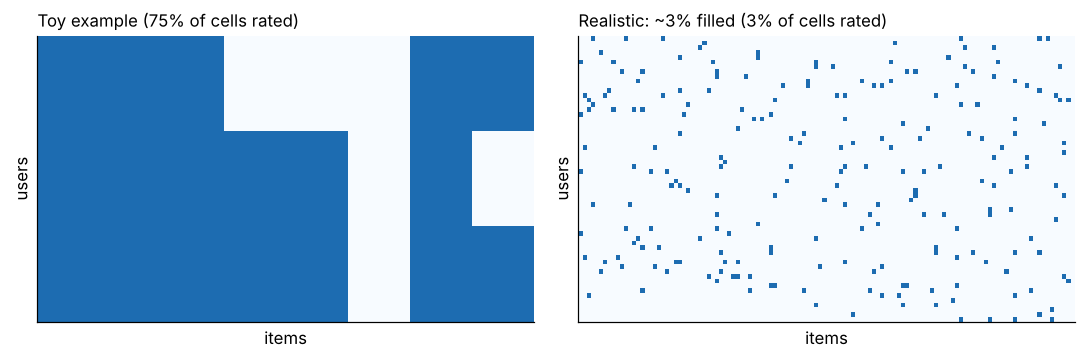

In [ ]:
#@title Figure: sparsity
rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, (n_u, n_i, fill, title) in zip(axes, [(3, 8, None, "Toy example"), (60, 120, 0.03, "Realistic: ~3% filled")]):
    M = (~np.isnan(R)).astype(float) if fill is None else (rng.random((n_u, n_i)) < fill).astype(float)
    ax.imshow(M, cmap="Blues", vmin=0, vmax=1.3, aspect="auto", interpolation="nearest")
    ax.set_title(f"{title} ({M.mean():.0%} of cells rated)", loc="left", fontsize=11)
    ax.set_xlabel("items"); ax.set_ylabel("users"); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

**2. Scalability.** Even the toy example needed several similarity calculations and weighted averages. With many users and items this gets slow, so the implementation must be efficient.

**3. Gray sheep and black sheep.** Picture users forming clusters of similar taste:
- **Gray sheep** sit *between* clusters, so it's unclear whose ratings to follow.
- **Black sheep** are far from *every* cluster, so there are no similar users to learn from.

(The video notes the black-sheep problem affects recommender systems in general, not only collaborative filtering.)

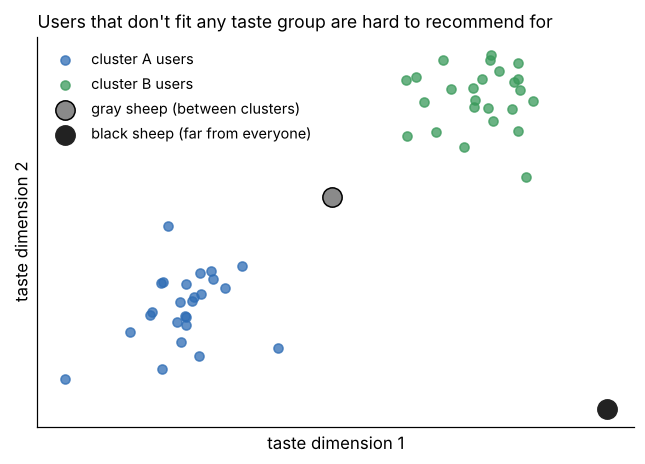

In [ ]:
#@title Figure: gray sheep and black sheep
rng = np.random.default_rng(1)
c1 = rng.normal([2, 2], 0.45, (25, 2)); c2 = rng.normal([5, 4.5], 0.45, (25, 2))
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.scatter(*c1.T, color=BLUE, alpha=0.75, label="cluster A users")
ax.scatter(*c2.T, color=GREEN, alpha=0.75, label="cluster B users")
ax.scatter([3.5], [3.25], s=160, color=GREY, edgecolor="k", zorder=3, label="gray sheep (between clusters)")
ax.scatter([6.3], [0.8], s=160, color="#222", zorder=3, label="black sheep (far from everyone)")
ax.set_xlabel("taste dimension 1"); ax.set_ylabel("taste dimension 2"); ax.set_xticks([]); ax.set_yticks([])
ax.legend(frameon=False, loc="upper left", fontsize=9.5)
ax.set_title("Users that don't fit any taste group are hard to recommend for", loc="left", fontsize=11.5)
plt.show()

## 10. Key takeaways
- Collaborative filtering = **"users similar to you liked this"**, using ratings only.
- Similarity is computed on the items **both users rated**. The video uses **cosine similarity** (angle between rating vectors).
- Prediction = **similarity-weighted average**, normalised by the sum of similarities.
- In the example, the plain average ties (3.5 vs 3.5), but the weighted average breaks the tie: **Show 5 (3.9) > Show 4 (3.1)**.
- Real-world problems: **sparsity, scalability, gray/black sheep**.

## 11. Connection to the first tutorial (my notes)
Same pipeline as the Valencia tutorial (similarity → weighted average). The difference is the similarity measure: cosine here, Euclidean/Pearson there.

One thing worth noticing: with ratings on a 1–5 scale, all values are positive, so **raw cosine similarity is always positive**. U1 and U3 clearly disagree, yet still get 0.57 and still pull the prediction toward U3's ratings. **Pearson** (which is cosine computed after subtracting each user's mean rating) gives a negative value for this pair. The cell below checks this.

In [ ]:
# Raw cosine vs Pearson (mean-centred cosine) for the same pairs
for other in (1, 2):
    _, x, y = common_pairs(0, other)
    cos_raw = x @ y / (np.linalg.norm(x) * np.linalg.norm(y))
    pearson = np.corrcoef(x, y)[0, 1]
    print(f"U1 vs {users[other]}:  cosine = {cos_raw:.2f}   Pearson = {pearson:+.2f}")

U1 vs U2:  cosine = 0.99   Pearson = +0.96
U1 vs U3:  cosine = 0.57   Pearson = -0.89


With Pearson, U3 would be treated as having *opposite* taste. In the Valencia-style `recommend()` (which skips negative similarities), U3 would be ignored and the predictions would follow U2 alone (Show 4 ≈ 2, Show 5 ≈ 5). Either way, the recommendation is still **Show 5**.

## 12. My notes / questions
- ...